# Hospital Readmissions in Pennsylvania, West Virginia and Maryland
**Solar Shrestha-Greene** · CMS Hospital Readmissions Reduction Program, FY 2026 (discharges Jul 2021 – Jun 2024)

**Goal:** find which hospitals and conditions in PA, WV and MD have more 30-day readmissions than Medicare expects, and how the three states compare with the nation.

**Key metric — Excess Readmission Ratio (ERR):** a hospital's predicted readmission rate divided by the rate expected for a similar hospital with similar patients. ERR above 1.0 = more readmissions than expected.

**Questions**
1. How do the three states compare with the national picture?
2. Which conditions are the biggest problem in each state?
3. Which hospitals perform best and worst across conditions?
4. Do hospitals with higher star ratings have fewer excess readmissions?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

ORANGE, NAVY, TEAL, GREY = "#f08a3c", "#0b1324", "#2a9d8f", "#cbd5e1"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("readmissions_pa_wv_md.csv", dtype={"facility_id": str, "zip": str})
national = pd.read_csv("national_benchmarks.csv")
print(df.shape, "|", df["facility_id"].nunique(), "hospitals |", df["period"].iloc[0])
df.head(3)

(1206, 21) | 201 hospitals | Jul 2021 - Jun 2024


,facility_id,hospital,address,city,county,state,state_name,zip,ownership,emergency_services,star_rating,condition,discharges,readmissions,predicted_rate_pct,expected_rate_pct,excess_ratio,performance,period,national_median_ratio,national_median_rate
0,210001,Meritus Medical Center,11116 Medical Campus Road,Hagerstown,Washington,MD,Maryland,21742,Voluntary non-profit - Private,Yes,3.0,Pneumonia,896.0,189.0,19.4437,15.6728,1.2406,Worse than expected,Jul 2021 - Jun 2024,0.9955,15.4479
1,210001,Meritus Medical Center,11116 Medical Campus Road,Hagerstown,Washington,MD,Maryland,21742,Voluntary non-profit - Private,Yes,3.0,Hip/knee replacement,NaN,NaN,5.1413,5.9028,0.8710,Better than or as expected,Jul 2021 - Jun 2024,0.9916,5.4153
2,210001,Meritus Medical Center,11116 Medical Campus Road,Hagerstown,Washington,MD,Maryland,21742,Voluntary non-profit - Private,Yes,3.0,Heart failure,657.0,127.0,19.6803,20.3089,0.9690,Better than or as expected,Jul 2021 - Jun 2024,0.9983,19.3125


## Step 1 — Check what's reported

CMS doesn't publish a result when a hospital has too few cases for a condition, or doesn't treat it at all (for example, bypass surgery at small hospitals).

In [2]:
print(df["performance"].value_counts(), "\n")
print("Reported results by condition:")
print(df[df["excess_ratio"].notna()].groupby("condition").size().sort_values(ascending=False))

rep = df[df["excess_ratio"].notna()].copy()
rep["worse"] = rep["excess_ratio"] > 1
print("\nResults analyzed:", len(rep), "from", rep["facility_id"].nunique(), "hospitals")

performance
Better than or as expected    427
Worse than expected           408
Not reported                  371
Name: count, dtype: int64 

Reported results by condition:
condition
Pneumonia               182
Heart failure           180
COPD                    165
Heart attack (AMI)      128
Hip/knee replacement    119
Heart bypass (CABG)      61
dtype: int64

Results analyzed: 835 from 189 hospitals


## Step 2 — How do the states compare with the nation?

National figure for context: across all 11,720 reported hospital-condition results in the US, **48.1%** are worse than expected.

               hospitals  results  share_worse  median_ratio
state_name                                                  
West Virginia         22       95        0.537         1.007
Pennsylvania         126      545        0.510         1.002
Maryland              41      195        0.405         0.980


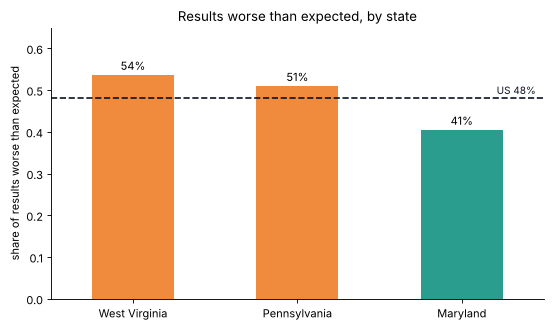

In [3]:
NATIONAL_SHARE_WORSE = 0.481   # from the full national file (all states), 11,720 reported results

by_state = (rep.groupby("state_name")
            .agg(hospitals=("facility_id", "nunique"), results=("worse", "size"),
                 share_worse=("worse", "mean"), median_ratio=("excess_ratio", "median"))
            .sort_values("share_worse", ascending=False))
print(by_state.round(3))

ax = by_state["share_worse"].plot(kind="bar", color=[ORANGE, ORANGE, TEAL], rot=0, figsize=(7, 4.2))
ax.axhline(NATIONAL_SHARE_WORSE, color=NAVY, ls="--", lw=1.5)
ax.text(2.45, NATIONAL_SHARE_WORSE + .01, f"US {NATIONAL_SHARE_WORSE:.0%}", ha="right", fontsize=9, color=NAVY)
for i, v in enumerate(by_state["share_worse"]):
    ax.text(i, v + .012, f"{v:.0%}", ha="center", fontsize=10)
ax.set_ylim(0, .65); ax.set_ylabel("share of results worse than expected"); ax.set_xlabel("")
ax.set_title("Results worse than expected, by state")
plt.tight_layout(); plt.savefig("worse_by_state.png", dpi=110); plt.show()

## Step 3 — Which conditions are the problem in each state?

state                   PA    WV    MD
condition                             
Heart attack (AMI)    0.57  0.54  0.47
COPD                  0.58  0.52  0.46
Heart failure         0.54  0.62  0.29
Pneumonia             0.40  0.62  0.37
Hip/knee replacement  0.43  0.31  0.55
Heart bypass (CABG)   0.59  0.50  0.18


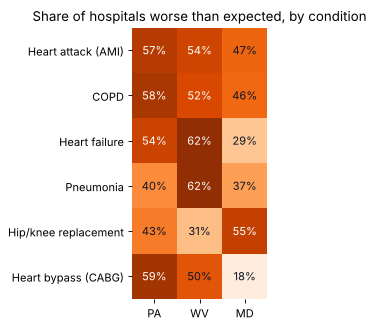

In [4]:
grid = rep.pivot_table(index="condition", columns="state", values="worse", aggfunc="mean")
grid = grid.loc[grid.mean(axis=1).sort_values(ascending=False).index, ["PA", "WV", "MD"]]
print(grid.round(2))

fig, ax = plt.subplots(figsize=(6, 4.2))
im = ax.imshow(grid.values, cmap="Oranges", vmin=0.15, vmax=0.65)
ax.set_xticks(range(3), ["PA", "WV", "MD"]); ax.set_yticks(range(len(grid)), grid.index)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=10, color="white" if v > .5 else NAVY)
ax.set_title("Share of hospitals worse than expected, by condition")
for s in ax.spines.values(): s.set_visible(False)
plt.tight_layout(); plt.savefig("condition_by_state.png", dpi=110); plt.show()

## Step 4 — Which hospitals stand out?

A hospital's overall score = its average ERR across the conditions it reports. Only hospitals with at least 3 reported conditions are ranked, so one condition can't decide the ranking.

Hospitals ranked: 172
Worse than expected on every condition: 10
Worse than expected on none: 12 

Best 10:
                                         hospital        city state  conditions  avg_ratio  conditions_worse  star_rating
                  MedStar Union Memorial Hospital   Baltimore    MD           6      0.901                 1          5.0
                  Garrett Regional Medical Center     Oakland    MD           4      0.905                 0          4.0
                         Meadville Medical Center   Meadville    PA           5      0.907                 1          4.0
                              Gettysburg Hospital  Gettysburg    PA           4      0.916                 0          4.0
                            Penn Highlands DuBois      Dubois    PA           6      0.916                 0          2.0
                      Sinai Hospital of Baltimore   Baltimore    MD           6      0.921                 1          3.0
                 WellSpan Good Samarit

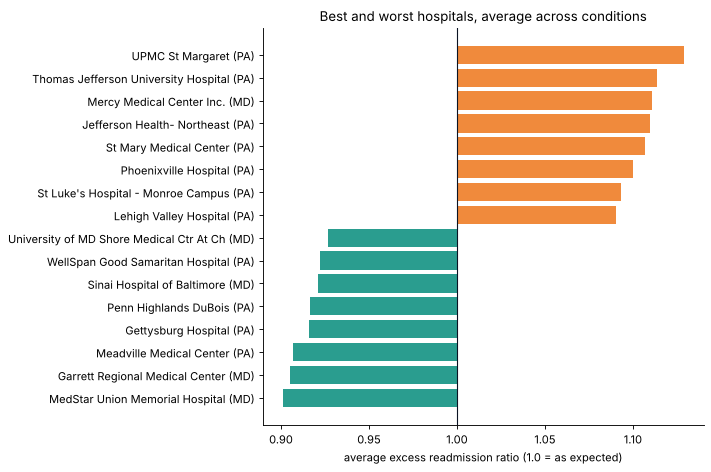

In [5]:
hosp = (rep.groupby(["facility_id", "hospital", "city", "state"])
        .agg(conditions=("excess_ratio", "size"), avg_ratio=("excess_ratio", "mean"),
             conditions_worse=("worse", "sum"), star_rating=("star_rating", "first"))
        .reset_index())
ranked = hosp[hosp["conditions"] >= 3].sort_values("avg_ratio")
print("Hospitals ranked:", len(ranked))
print("Worse than expected on every condition:", (ranked["conditions_worse"] == ranked["conditions"]).sum())
print("Worse than expected on none:", (ranked["conditions_worse"] == 0).sum(), "\n")

cols = ["hospital", "city", "state", "conditions", "avg_ratio", "conditions_worse", "star_rating"]
print("Best 10:"); print(ranked.head(10)[cols].round(3).to_string(index=False))
print("\nWorst 10:"); print(ranked.tail(10)[cols].iloc[::-1].round(3).to_string(index=False))

show = pd.concat([ranked.head(8), ranked.tail(8)])
show["label"] = show["hospital"].str.slice(0, 40) + " (" + show["state"] + ")"
show = show.sort_values("avg_ratio")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(show["label"], show["avg_ratio"] - 1, left=1,
        color=[TEAL if v <= 1 else ORANGE for v in show["avg_ratio"]])
ax.axvline(1, color=NAVY, lw=1)
ax.set_xlabel("average excess readmission ratio (1.0 = as expected)")
ax.set_title("Best and worst hospitals, average across conditions")
plt.tight_layout(); plt.savefig("best_worst_hospitals.png", dpi=110); plt.show()

In [6]:
local = hosp[hosp["hospital"].str.contains("Garrett|Uniontown|Mon Health|UPMC Somerset|Allegheny General", case=False)]
print("Hospitals near Deep Creek Lake, Morgantown and Pittsburgh:")
print(local[cols].round(3).to_string(index=False))
garrett = ranked.reset_index(drop=True)
print("\nGarrett Regional Medical Center rank:", garrett.index[garrett["hospital"].str.contains("Garrett")][0] + 1, "of", len(garrett))

Hospitals near Deep Creek Lake, Morgantown and Pittsburgh:
                       hospital       city state  conditions  avg_ratio  conditions_worse  star_rating
Garrett Regional Medical Center    Oakland    MD           4      0.905                 0          4.0
                  UPMC Somerset   Somerset    PA           3      0.993                 1          4.0
             Uniontown Hospital  Uniontown    PA           4      1.025                 3          2.0
     Allegheny General Hospital Pittsburgh    PA           6      1.032                 4          3.0
      Mon Health Medical Center Morgantown    WV           6      1.001                 2          4.0

Garrett Regional Medical Center rank: 2 of 172


## Step 5 — Do star ratings line up with readmissions?

             count   mean
star_rating              
1.0              9  1.028
2.0             35  1.014
3.0             53  1.010
4.0             58  0.994
5.0             23  0.983
Correlation, star rating vs average ratio: -0.29


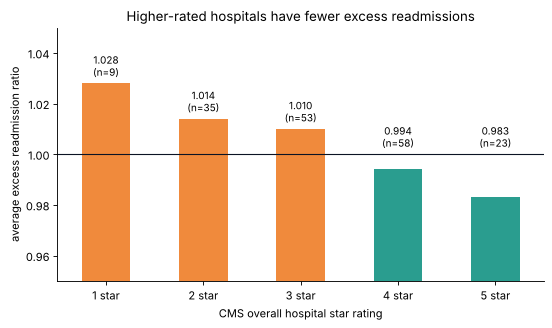

In [7]:
stars = hosp.dropna(subset=["star_rating"]).groupby("star_rating")["avg_ratio"].agg(["count", "mean"]).round(3)
print(stars)
print("Correlation, star rating vs average ratio:", hosp[["star_rating", "avg_ratio"]].corr().iloc[0, 1].round(2))

ax = stars["mean"].plot(kind="bar", color=[ORANGE if v > 1 else TEAL for v in stars["mean"]], rot=0, figsize=(7, 4.2))
ax.axhline(1, color=NAVY, lw=1)
for i, (v, n) in enumerate(zip(stars["mean"], stars["count"])):
    ax.text(i, max(v, 1) + .003, f"{v:.3f}\n(n={n})", ha="center", fontsize=9)
ax.set_ylim(.95, 1.05); ax.set_xticklabels([f"{int(s)} star" for s in stars.index])
ax.set_ylabel("average excess readmission ratio"); ax.set_xlabel("CMS overall hospital star rating")
ax.set_title("Higher-rated hospitals have fewer excess readmissions")
plt.tight_layout(); plt.savefig("ratio_by_star.png", dpi=110); plt.show()

In [8]:
# Excess readmissions: (predicted rate - expected rate) x discharges, where CMS reports discharges
rep["excess_readmissions"] = (rep["predicted_rate_pct"] - rep["expected_rate_pct"]) / 100 * rep["discharges"]
over = rep[rep["excess_readmissions"] > 0]
print("Results with discharge counts:", rep["excess_readmissions"].notna().sum())
print(f"Readmissions above expected at hospitals doing worse than expected: {over['excess_readmissions'].sum():,.0f}")
print(over.groupby("state")["excess_readmissions"].sum().round(0))

Results with discharge counts: 593
Readmissions above expected at hospitals doing worse than expected: 924
state
MD    162.0
PA    637.0
WV    125.0
Name: excess_readmissions, dtype: float64


## Findings and recommendations

| Question | Finding | Recommendation |
|---|---|---|
| States vs nation | West Virginia (54%) and Pennsylvania (51%) have more results worse than expected than the US (48%); Maryland is lower at 41%. | Focus readmission-reduction programs in PA and WV hospitals. |
| Conditions | Heart failure and pneumonia are the weak spots in WV (62% of hospitals worse than expected); in PA, bypass surgery, COPD and heart attack are all near 58%. | Target discharge planning and follow-up care for these conditions by state. |
| Hospitals | 10 of 172 ranked hospitals are worse than expected on every condition they report; 12 are worse on none. | Study the consistent performers' discharge processes and share them across systems. |
| Star ratings | Average ratio falls steadily from 1.028 (1-star) to 0.983 (5-star); correlation −0.29. | Readmissions track overall quality, so quality programs should include readmission follow-up. |
| Local | Garrett Regional Medical Center (Oakland, MD) ranks 2nd of 172, better than expected on all 4 conditions it reports. | A small rural hospital can match large academic centers on readmissions. |

**Limitations:** results cover Medicare patients only; Maryland hospitals are exempt from HRRP payment penalties under the state's own Medicare model; small hospitals often have too few cases to report; the average ratio across conditions weights each condition equally regardless of patient volume.